# Main Figure 2

This notebook is dedicated to produce the content of [Pepe, Mariani et al. 2026](https://www.biorxiv.org/content/10.64898/2026.02.05.704055v1.full) figure 2. It relies on the ["Structural and dynamic embedding of the mouse functional connectome revealed by functional ultrasound imaging (fUSI)"](10.5281/zenodo.18486492) dataset publically available on Zenodo. Absolute paths MUST be adapted to your local environment. The structure of the notebook is as follow:

- Import of packages
- Local helper functions
- Definition of general parameters
- 4 sections associated to each subpannel of the figure
    - `**Display Maps**` gets a collection of `.nii.gz` statistical maps representing funcitonal connectivity (FC) in the native four slices space as described in the article and upsample them to the equivalent four slices of the Allen Brain Atlas (ABA) before displaying them in high resolution
    - `**fMRI/fUSI comparison**` gets a collection of `.nii.gz` statistical maps for both `fMRI` and `fUSI` from the `derivative/analysis/SBA` folder and estimates their similiarity
    - `**Correlation Matrix**` gets a collection of `.nii.gz` 4D time series, computes and shows population FC matrix based on ABA ontologoy and data based clustering method
    - `**ICA**` gets a collection of `.nii.gz` 4D time series and estimate Independent Component based on dictionary learning methods as detailed in [nilearn documentation](https://nilearn.github.io/stable/auto_examples/03_connectivity/plot_compare_decomposition.html).

In [2]:
# Packages, classes and functions to import

import re

import numpy as np
import colorcet as cc
import nibabel as nib
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colorbar import ColorbarBase
import scipy.stats as stats

from pathlib import Path
from tqdm import tqdm
from rastermap import Rastermap

from nilearn.masking import apply_mask, unmask
from nilearn.image import math_img, resample_img
from nilearn.maskers import NiftiLabelsMasker
from nilearn.decomposition import CanICA, DictLearning
from matplotlib.patches import Polygon
from scipy.ndimage import binary_fill_holes, zoom, gaussian_filter, binary_dilation, binary_erosion
from scipy.stats import gaussian_kde, wilcoxon
from statsmodels.stats.multitest import multipletests
from nilearn.decomposition import DictLearning
from scipy.ndimage import gaussian_filter1d

# Helper function

In [47]:
def density_profile(xs, data, bw=0.3):

    """
    Estimate the probability density function of a one-dimensional dataset
    using Gaussian kernel density estimation (KDE).

    A Gaussian kernel density estimator is fitted to the input data and
    evaluated at the specified sample locations.

    Parameters
    ----------
    xs : array-like
        One-dimensional array of points at which to evaluate the estimated
        probability density function.
    data : array-like
        One-dimensional sample used to fit the kernel density estimator.
    bw : float or str, optional
        Bandwidth parameter passed to ``scipy.stats.gaussian_kde`` as
        ``bw_method``. Smaller values produce a less smoothed estimate,
        whereas larger values produce a smoother density estimate.
        Default is 0.3.

    Returns
    -------
    ndarray
        Estimated probability density evaluated at each point in ``xs``.

    Notes
    -----
    This function uses ``scipy.stats.gaussian_kde`` with a Gaussian kernel.
    The estimated density integrates to one over its domain.
    """
    
    kde = gaussian_kde(data, bw_method=bw)
    
    return kde(xs)

def custom_join_plot(
    x,
    y,
    dpi=200,
    figsize=(5, 5),
    nb_ticks=5,
    fill_alpha=0.20,
    n_bins=20,
    #smooth_std=True
):

    """
    Create a joint scatter plot with linear regression, marginal density
    estimates, and a local residual-variability envelope.

    The central panel displays the paired observations together with an
    ordinary least-squares regression line. A local variability band is
    estimated by dividing the x-axis into bins and computing the standard
    deviation of the regression residuals within each bin. Kernel density
    estimates of ``x`` and ``y`` are shown in the top and right marginal
    panels, respectively.

    The Pearson correlation coefficient associated with the fitted linear
    regression is displayed in the central panel.

    Parameters
    ----------
    x : array-like of shape (n_samples,)
        Values plotted along the horizontal axis. The input must contain
        finite numeric values and have the same length as ``y``.
    y : array-like of shape (n_samples,)
        Values plotted along the vertical axis. The input must contain
        finite numeric values and have the same length as ``x``.
    dpi : int, optional
        Resolution of the created figure in dots per inch. Default is 200.
    figsize : tuple of float, optional
        Figure dimensions in inches, specified as ``(width, height)``.
        Default is ``(5, 5)``.
    nb_ticks : int, optional
        Intended number of ticks on the main x- and y-axes. Default is 5.

        Notes
        -----
        In the current implementation, this argument is overwritten internally
        with a value of 3 and therefore does not affect the output.
    fill_alpha : float, optional
        Opacity of the local residual-variability envelope around the
        regression line. Values should generally lie between 0 and 1.
        Default is 0.20.
    n_bins : int, optional
        Number of bin edges used to estimate local residual variability.
        This produces ``n_bins - 1`` intervals along the x-axis.
        Default is 20.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Matplotlib figure containing the joint plot.
    ax : ndarray of matplotlib.axes.Axes, shape (2, 2)
        Array of axes containing the top marginal density, central scatter
        plot, and right marginal density. The unused corner axes are hidden.

    Notes
    -----
    The regression is computed using ``scipy.stats.linregress``.

    Marginal densities are estimated using ``density_profile``, which is
    expected to apply Gaussian kernel density estimation.

    For bins containing more than one observation, the local variability is
    calculated as the sample standard deviation of the regression residuals.
    For bins containing one observation, the absolute residual is used. Empty
    bins inherit the value from the preceding non-empty bin, or zero if the
    first bin is empty.
    """
    
    xylim = [x.min(), x.max(), y.min(), y.max()]
    xs = np.linspace(xylim[0], xylim[1], 200)

    pearsonr = stats.linregress(x, y)
    ys = pearsonr.intercept + pearsonr.slope * xs

    # p-value formatting
    if pearsonr.pvalue > 0.01:
        p_val = f'p = {pearsonr.pvalue:.2f}'
    elif pearsonr.pvalue > 0.001:
        p_val = f'p < 0.01'
    elif pearsonr.pvalue > 0.0001:
        p_val = f'p < 0.001'
    elif np.log10(pearsonr.pvalue) > -10:
        p_val = f'p < $10^{{{np.ceil(np.log10(pearsonr.pvalue))}}}$'
    else:
        p_val = f'p < $10^{{-10}}$'

    # --- Local ±1 std around regression line ---
    bin_edges = np.linspace(xylim[0], xylim[1], n_bins)
    local_std = []

    for start, end in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (x > start) & (x <= end)
        x_bin = x[mask]
        y_bin = y[mask]
        if len(y_bin) > 1:
            y_pred = pearsonr.intercept + pearsonr.slope * x_bin
            residuals = y_bin - y_pred
            std_val = np.sqrt((residuals**2).sum() / (len(y_bin) - 1))
        elif len(y_bin) == 1:
            y_pred = pearsonr.intercept + pearsonr.slope * x_bin
            std_val = np.abs(y_bin - y_pred)[0]
        else:
            std_val = local_std[-1] if local_std else 0
        local_std.append(std_val)

    xci = (bin_edges[:-1] + bin_edges[1:]) / 2
    yci = pearsonr.intercept + pearsonr.slope * xci

    #if smooth_std:
     #   local_std = gaussian_filter1d(local_std, sigma=1)

    # --- Plotting ---
    fig, ax = plt.subplots(2, 2, figsize=figsize, dpi=dpi,
                           gridspec_kw={'height_ratios': [1.5, 7], 'width_ratios': [7, 1.5]})

    ax[0, 0].axis('off')
    ax[0, 1].axis('off')
    ax[1, 1].axis('off')

    # Top density
    top_density = density_profile(xs, x, bw=0.15)
    ax[0, 0].fill_between(xs, top_density, 0, facecolor='C1', edgecolor='none', alpha=0.6)
    ax[0, 0].plot(xs, top_density, color='darkorange', linewidth=2.5)
    ax[0, 0].set_xlim(x.min(), x.max())
    ax[0, 0].set_ylim(0, top_density.max() * 1.1)

    # Right density
    ys_density = np.linspace(y.min(), y.max(), 200)
    right_density = density_profile(ys_density, y, bw=0.15)
    ax[1, 1].fill_betweenx(ys_density, 0, right_density, facecolor='C1', edgecolor='none', alpha=0.6)
    ax[1, 1].plot(right_density, ys_density, color='darkorange', linewidth=2.5)
    ax[1, 1].set_ylim(y.min(), y.max())
    ax[1, 1].set_xlim(0, right_density.max() * 1.1)

    # Local std fill
    ax[1, 0].fill_between(
        xci,
        yci - local_std,
        yci + local_std,
        color='C3',
        alpha=fill_alpha,
        edgecolor=None,
        zorder=5
    )

    # Polygon outline 
    std_outline = Polygon(
        np.stack([
            np.concatenate([xci, np.flip(xci)]),
            np.concatenate([yci + local_std, np.flip(yci - local_std)])
        ]).T,
        fill=False,
        color='C3',
        linewidth=1.5,
        alpha=0,
        zorder=6
    )
    ax[1, 0].add_patch(std_outline)

    # Scatter
    ax[1, 0].scatter(
        x,
        y,
        s=180,
        facecolor=(1.0, 0.55, 0.0, 0.1),
        edgecolor='darkorange',
        linewidth=0.7,
        zorder=3
    )

    # Regression line
    ax[1, 0].plot(xs, ys, c='k', linewidth=5, zorder=4)

    # Axis ticks
    [xm, xM, ym, yM] = ax[1, 0].axis()

    # Set number of ticks
    nb_ticks = 3  # or whatever number you want
    
    # Compute xticks
    local_xM = ((((np.floor(xM * 10) // (nb_ticks - 1))) + 1) * (nb_ticks - 1) / 10)
    xticks = [np.round(x, 1) for x in np.arange(nb_ticks) * local_xM / (nb_ticks - 1)]
    
    # Compute yticks
    local_yM = ((((np.floor(yM * 10) // (nb_ticks - 1))) + 1) * (nb_ticks - 1) / 10)
    yticks = [np.round(x, 1) for x in np.arange(nb_ticks) * local_yM / (nb_ticks - 1)]
    
    # Apply ticks
    ax[1, 0].set_xticks(xticks)
    ax[1, 0].set_yticks(yticks)


    ax[0, 0].set_xlim(xm, xM)
    ax[1, 1].set_ylim(ym, yM)

    # Styling
    for spine_name, spine in ax[1, 0].spines.items():
        spine.set_visible(spine_name in ['bottom', 'left'])
        if spine_name in ['bottom', 'left']:
            spine.set_linewidth(3)
    ax[1, 0].tick_params(width=3, length=5, labelsize=26)

        # Text annotation (r only, no p-value)
    ax[1, 0].text(0.25 * xM, 0.9 * yM, f'r = {pearsonr.rvalue:.2f}',
                  ha='center', fontsize=26)

    plt.tight_layout()

    return fig, ax

def standardize(signals):

    """
    Standardize each signal independently to zero mean and unit variance.

    Each column of the input array is standardized by subtracting its mean
    and dividing by its standard deviation. Mean and standard deviation are
    computed using ``numpy.nanmean`` and ``numpy.nanstd``, respectively, so
    NaN values are ignored during the computation.

    Parameters
    ----------
    signals : ndarray of shape (n_samples, n_signals)
        Input signal matrix where each column corresponds to a signal (e.g.,
        a parcel-wise or voxel-wise time series) and each row corresponds to
        an observation or time point.

    Returns
    -------
    ndarray of shape (n_samples, n_signals)
        Standardized signal matrix with each column having approximately zero
        mean and unit variance, ignoring NaN values.

    Notes
    -----
    If a signal contains only NaN values or has zero variance, the
    corresponding standardized values will be NaN due to division by zero.
    """
    
    signals_out = []
    for x in signals.T:
        
        signals_out.append((x-np.nanmean(x))/np.nanstd(x))
    
    return np.array(signals_out).T

def display_modes(img, nb_col = 4, cmap = cc.cm['CET_D1'], vmin = -1, vmax = 1):

    """
    Display the slices of a volumetric image as a row of subplots.

    The function extracts ``nb_col`` slices along the first
    dimension of the input image and displays them using the specified
    colormap and intensity range. It is primarily intended for visualizing
    spatial modes or components stored as successive slices of a NIfTI image.

    Parameters
    ----------
    img : nibabel.spatialimages.SpatialImage
        Input volumetric image. The first dimension is assumed to index the
        modes or slices to display.
    nb_col : int, optional
        Number of slices (or modes) to display. The first ``nb_col`` slices
        along the first dimension are shown. Default is 4.
    cmap : matplotlib.colors.Colormap, optional
        Colormap used to display the image. Default is ``cc.cm['CET_D1']``.
    vmin : float, optional
        Lower bound of the displayed intensity range. Default is -1.
    vmax : float, optional
        Upper bound of the displayed intensity range. Default is 1.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Matplotlib figure containing the displayed slices.

    Notes
    -----
    The displayed images use a fixed aspect ratio of ``0.1 / 0.11`` as default 
    native fUSI aspect and the subplot axes are hidden.
    """
    
    fig, ax = plt.subplots(1,nb_col, figsize = (nb_col*6,5), dpi = 200, facecolor = 'k')
                
    for i in range(nb_col):

        img2display = img.get_fdata()[i,:,:]

        ax[i].imshow((img2display), cmap = cmap, vmin = vmin, vmax = vmax, aspect = 0.1/0.11)
        ax[i].axis('off')
        
    return fig

def extract_signal(img, roi):
    
    """
    Extract and standardize the mean time series from a region of interest.

    The function computes the average signal across all voxels within the
    specified ROI for each time point and standardizes the resulting time
    series to zero mean and unit variance.

    Parameters
    ----------
    img : nibabel.spatialimages.SpatialImage
        Input 4D functional image from which to extract the signal.
    roi : nibabel.spatialimages.SpatialImage or str or pathlib.Path
        Binary mask defining the region of interest. Non-zero voxels are
        included in the signal extraction.

    Returns
    -------
    ndarray of shape (n_samples,)
        Standardized mean time series extracted from the ROI.

    Notes
    -----
    Signal extraction is performed using ``nilearn.masking.apply_mask``.
    The extracted time series is standardized by subtracting its mean and
    dividing by its standard deviation. If the extracted signal has zero
    variance, the returned values will be NaN due to division by zero.
    """
    
    signal = apply_mask(img, roi).mean(1)
    signal = (signal-signal.mean())/signal.std()
    
    return signal

def compute_correlation_matrix(
    file_name,
    roi_list
):

    """
    Compute the ROI-wise Pearson correlation matrix from a 4D functional image.

    The input image is loaded from disk and the mean time series is extracted
    independently from each region of interest (ROI) in ``roi_list``. Signal
    extraction is parallelized using ``joblib``. The Pearson correlation
    coefficient is then computed between every pair of standardized ROI time
    series to produce a symmetric correlation matrix.

    Parameters
    ----------
    file_name : str or pathlib.Path
        Path to the 4D functional image.
    roi_list : sequence
        Sequence of ROI masks. Each element should be compatible with
        ``extract_signal`` (e.g., a nibabel spatial image or a path to a
        binary mask image).

    Returns
    -------
    ndarray of shape (n_rois, n_rois)
        Pearson correlation matrix between the extracted ROI time series.

    Notes
    -----
    ROI signals are extracted using ``extract_signal``, which standardizes
    each time series to zero mean and unit variance prior to computing the
    correlations.

    Signal extraction is parallelized using ``joblib.Parallel`` together
    with ``tqdm_joblib`` to provide a progress bar.
    """
    
    # Computes the correlation matrix of on timeseries based on a list of ROIs
    
    nb_parcels = len(roi_list)
    
    # loads image
    
    img = nib.load(file_name)
    
    # extracts signals
        
    with tqdm_joblib(desc=f"extracting signals...", total=len(roi_list)) as progress_bar:

        signals = Parallel(n_jobs=18)(delayed(extract_signal)(
            img,
            roi
        ) for roi in roi_list)
        
    cor_mat = np.zeros((nb_parcels, nb_parcels))
        
    for i in range(nb_parcels):
        for j in range(nb_parcels):
            
            cor_mat[i,j] = np.corrcoef(signals[i], signals[j])[0,1]
            
    return cor_mat

def from_mat_2_vect(mat):

    """
    Vectorize the lower triangular part of a square matrix.

    The function extracts the elements of the strictly lower triangular
    portion of the input matrix (excluding the diagonal) and returns them as
    a one-dimensional array in row-major order. This representation is
    commonly used to store symmetric matrices, such as correlation or
    connectivity matrices, without redundant entries.

    Parameters
    ----------
    mat : ndarray of shape (n, n)
        Square input matrix.

    Returns
    -------
    ndarray of shape (n * (n - 1) // 2,)
        One-dimensional array containing the elements of the strictly lower
        triangular part of ``mat``, ordered row by row.

    Notes
    -----
    The diagonal elements are excluded from the output. For symmetric
    matrices, the returned vector contains all unique off-diagonal entries.
    """
    
    nb_parcels = mat.shape[0]
    
    vect = mat[np.tril(np.ones((nb_parcels, nb_parcels)), -1).astype(bool)]
    
    return vect


def from_vect_2_mat(vect):

    """
    Reconstruct a symmetric matrix from its vectorized lower triangular part.

    The input vector is assumed to contain the elements of the strictly lower
    triangular part of a square matrix (excluding the diagonal), ordered
    row by row as produced by ``from_mat_2_vect``. The function reconstructs
    the full symmetric matrix by filling the lower triangle and copying its
    values to the upper triangle. The diagonal elements are set to zero.

    Parameters
    ----------
    vect : array-like of shape (n * (n - 1) // 2,)
        One-dimensional array containing the elements of the strictly lower
        triangular part of a symmetric matrix.

    Returns
    -------
    ndarray of shape (n, n)
        Symmetric matrix reconstructed from ``vect`` with a zero diagonal.

    Notes
    -----
    The diagonal of the reconstructed matrix is initialized to zero.
    The function is the inverse operation of ``from_mat_2_vect`` for
    symmetric matrices.
    """
    
    L = len(vect)
    nb_parcels = int(0.5*(1+np.sqrt(1+8*L)))
    
    mat = np.zeros((nb_parcels, nb_parcels))
    
    mat[np.tril(np.ones((nb_parcels, nb_parcels)), -1).astype(bool)] = vect
    for i in range(nb_parcels):
        for j in range(i):
            mat[j,i] = mat[i,j]
    
    return mat

def fill_holes_sw(img_2_display):
    
    """
    Fill holes and smooth labeled regions in a segmentation image.

    Each non-zero label is processed independently by applying a sequence of
    binary morphological operations consisting of dilation, hole filling, and
    erosion. The processed binary mask is then assigned its original label in
    the output image. Background voxels (label 0) are left unchanged.

    Parameters
    ----------
    img_2_display : ndarray
        Two-dimensional or three-dimensional labeled image. Each unique
        non-zero value is interpreted as an independent region.

    Returns
    -------
    ndarray
        Labeled image with holes filled and region boundaries smoothed.
        The output has the same shape as the input.

    Notes
    -----
    For each label, the following operations are applied in sequence:

    1. Binary dilation.
    2. Binary hole filling.
    3. Binary erosion.

    This sequence is equivalent to a binary closing followed by hole filling
    and is useful for removing small holes and smoothing irregular boundaries
    while approximately preserving the original object size.

    Labels are processed independently, so adjacent labeled regions may
    compete for voxels if the dilation step causes them to overlap.
    The last processed label takes precedence in overlapping regions.
    """
    
    img_out = np.zeros(img_2_display.shape)
    
    for k in np.unique(img_2_display):
        
        if k !=0 :
            
            mask = (img_2_display == k).astype(float)
            mask = binary_erosion(binary_fill_holes(binary_dilation(mask)))
            img_out[mask>0] = k
            
    return img_out

def smooth_high_res_cluster(
    img_2_display,
    sigma = 2.,
    th = 0.5
):

    """
    Smooth labeled regions in a segmentation image using Gaussian filtering
    and morphological erosion.

    Each non-zero label is processed independently by converting it to a
    binary mask, applying Gaussian smoothing, thresholding the smoothed mask,
    and eroding the resulting region. The processed mask is then assigned its
    original label in the output image. Background voxels (label 0) remain
    unchanged.

    Parameters
    ----------
    img_2_display : ndarray
        Two-dimensional or three-dimensional labeled image. Each unique
        non-zero value is interpreted as an independent region.
    sigma : float, optional
        Standard deviation of the Gaussian kernel used to smooth each binary
        mask prior to thresholding. Larger values produce smoother region
        boundaries. Default is 2.0.
    th : float, optional
        Threshold applied to the smoothed binary mask. Voxels with values
        greater than ``th`` are retained in the processed region.
        Default is 0.5.

    Returns
    -------
    ndarray
        Labeled image with smoothed and morphologically eroded regions. The
        output has the same shape as the input.

    Notes
    -----
    For each label, the following operations are applied in sequence:

    1. Convert the labeled region to a binary mask.
    2. Apply Gaussian smoothing using ``scipy.ndimage.gaussian_filter``.
    3. Threshold the smoothed mask.
    4. Perform binary erosion with five iterations.

    Labels are processed independently. If smoothing causes neighboring
    regions to overlap, the last processed label takes precedence in the
    overlapping voxels.
    """
    
    img_out = np.zeros(img_2_display.shape)
    
    for k in np.unique(img_2_display):
        
        if k !=0 :
            
            mask = 1.*(img_2_display == k)
            mask = gaussian_filter(mask, sigma)>th
            mask = binary_erosion(mask, iterations=5)
            img_out[mask>0] = k

    return img_out
    

# General Parameters

parameters which apply for the entire notebook.

In [16]:
########################## Display parameter

# fUSI number of slices
nb_col = 4

########################## Parameter images

# Allen template 
template_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/templates/source-Wang2020_space-fUSIswVBm40_desc-AllenTemplate_res-110umx100umx100um_pose-vol_feature.nii.gz')
template_img = nib.load(template_name)

# Allen mask
mask_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/templates/source-Wang2020_space-fUSIswVBm40_desc-AllenMask_res-110umx100umx100um_pose-vol_feature.nii.gz')
mask_img = nib.load(mask_name)

################ Template high resolution

template_hr_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/templates/source-Wang2020_space-fUSIswVBm40_desc-AllenTemplate_res-25umx25umx25um_pose-vol_feature.nii.gz')
template_hr_img = nib.load(template_hr_name)

[X,Y,Z] = template_hr_img.shape
template_vmin = template_hr_img.get_fdata()[int(X/2)-50:int(X/2)+50,int(Z/2)-50:int(Z/2)+50].min()
template_vmax = template_hr_img.get_fdata()[int(X/2)-50:int(X/2)+50,int(Z/2)-50:int(Z/2)+50].max()

################ Parcellation
    
parcellation_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/parcellations/source-gozzilab_space-fUSI100_desc-parcellationUnilateralDefaultN54_res-100umx100umx100um_pose-vol_feature.nii.gz')
parcellation = nib.load(parcellation_name)
acro_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/parcellations/source-gozzilab_space-fUSI100_desc-parcellationUnilateralDefaultN54_res-100umx100umx100um_pose-vol_feature.csv')
acro_df = pd.read_csv(acro_name)


output_root = Path('/media/DATA/jmariani/2_Results/2026-05-07_PepeMariani/Main-figure_02')
output_root.mkdir(exist_ok = True, parents = True)

## Colorbar

Loads and displays the colorbar

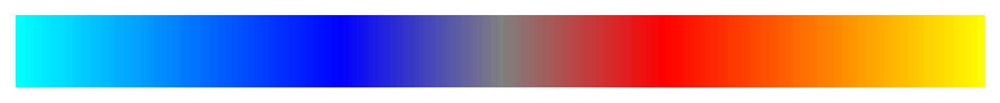

In [18]:
cmap_name = '../libraries/colourmaps/render3.cmap'

with open(cmap_name, 'r') as f:
    
    lines = f.readlines()
    
cmap_list = [[float(y) for y in x.split('\n')[0].split(' ')] for x in lines]

mymap = mcolors.ListedColormap(cmap_list)

fig, ax = plt.subplots(figsize=(8, 0.6), dpi=300)
cb = ColorbarBase(ax, cmap=mymap, orientation='horizontal')
cb.set_ticks([])
cb.outline.set_visible(False)
ax.set_axis_off()
fig.patch.set_alpha(0)

save_path = output_root / f'colorbar.svg'

plt.savefig(save_path, format="svg", transparent=True, bbox_inches="tight", pad_inches=0)

# Display maps

## Parameters

In [19]:
# Parameters

########################## Parameter display

# Symmetrical display threshold above 2.1 (mass univariate t-test alpha = 5%), saturates at 8 (heuristic for one sampled mass univariate t-test)
vmin = 2.1
vmax = 8

########################## Maps

fusi_root_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/analysis/SBA/fUSI/REGaCompCor_fUSI/')

########################## seeds

roi_root= Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/rois/whole-ROI_CP-20/00_left_single-slice/')

parcellation_tag = 'parcellationUnilateralDefaultN54'
roi_type = 'Left-singleSlice'

########################## Output structure

save_dir = output_root / Path('fUSI-SBA')
save_dir.mkdir(exist_ok = True, parents = True)

## Loading

Loads data structure in lists and displays files for checks.

In [20]:
roi_list = []
seed_list = []

print(f'Seeds:\n\n')

for x in sorted(roi_root.iterdir()):
    if x.is_file():
        print(x.name)
        seed_list.append(x)
        roi_list.append(x.name.split(f'{parcellation_tag}-')[1].split(f'-{roi_type}')[0])

fusi_list = []

for roi in roi_list:
    
    # fUSI
    file_name = [x for x in fusi_root_name.iterdir() if x.is_file() and re.match(f'^.*{roi}.*Tstat_cc_t2.1_p0.05.nii.gz$', x.name)][0]
    fusi_list.append(file_name)

print(f'\n\nfUSI:\n\n')
for x in fusi_list:
    print(x.name)

Seeds:


parcellationUnilateralDefaultN54-ROI-1-MOp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-10-SSs-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-15-AUDv-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-18-VISp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-19-AIp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-2-MOs-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-22-ACA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-23-RSPd-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-25-PTLp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-29-PIR-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-30-COA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-32-CA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-33-DG-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-45-STRd-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-4

## Display


In [21]:
for file_name, roi_name, roi_id in tqdm(zip(fusi_list, seed_list, roi_list)):

    # Loads low resolution images
    
    sbm_img = nib.load(file_name)
    roi_img = nib.load(roi_name)

    # upsample SBM and ROI
    
    sbm_hr_img = resample_img(
        sbm_img,
        target_affine=template_hr_img.affine,
        target_shape=template_hr_img.shape,
        interpolation='continuous',
        copy_header=True,
        force_resample=True
    )
    
    roi_hr_img = resample_img(
        roi_img,
        target_affine=template_hr_img.affine,
        target_shape=template_hr_img.shape,
        interpolation='nearest',
        copy_header=True,
        force_resample=True
    )
    
    # Display
    
    nb_col = 4
    
    fig,ax = plt.subplots(1,nb_col, figsize = (7*nb_col, 5), dpi = 200)
    
    for slice_id in range(nb_col):
        
        ######################## Template
    
        img_2_display = template_hr_img.get_fdata()[slice_id,:,:].copy()
        current_mask = 1.*(binary_fill_holes(img_2_display>10))
        img_2_display[current_mask == 0] = np.nan
    
        ax[slice_id].imshow(img_2_display, cmap = 'Greys_r', vmin = template_vmin, vmax = template_vmax)
    
        # ######################## image
    
        # smoothing kernel matches the upsampling factor from fUSI 100um to Allen 25um
        img_2_display = gaussian_filter(sbm_hr_img.get_fdata()[slice_id,:,:].copy(), sigma = 4)
        img_2_display[current_mask == 0] = 0
    
        ax[slice_id].imshow(img_2_display, cmap = mymap, vmin = -vmax, vmax = vmax, alpha = 0.7*(abs(img_2_display)>vmin), interpolation = 'nearest')
    
        # ######################## ROI Contour
    
        img_2_display = gaussian_filter(1.*(roi_hr_img.get_fdata()[slice_id,:,:].copy()>0.5), sigma = 8)>0.25
        img_2_display = img_2_display*current_mask
        
        ax[slice_id].contour(img_2_display, levels = [0.5], colors = ['k'], linewidths = [2])
        
        ax[slice_id].axis('off')
        
        # ######################## Mask Contour
        
        ax[slice_id].contour(gaussian_filter(1.*current_mask,2), levels = [0.5], colors = ['k'], linewidths = [4])
        
        ax[slice_id].axis('off')
    
    plt.tight_layout()

    save_name = save_dir / f'SBA_ROI-{roi_id}.png'
    plt.savefig(save_name)
    save_name = save_dir / f'SBA_ROI-{roi_id}.svg'
    plt.savefig(save_name)

    plt.close('all')

20it [01:07,  3.38s/it]


# fMRI/fUSI comparison

## Parameters


In [22]:
##########################      maps

fmri_root_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/analysis/SBA/fMRI/REGaCompCor-fMRI-29/')
fusi_root_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/analysis/SBA/fUSI/REGaCompCor_fUSI/')

##########################      seeds

roi_root= Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/Params/fusi/volume/rois/whole-ROI_CP-20/00_left_single-slice/')

parcellation_tag = 'parcellationUnilateralDefaultN54'
roi_type = 'Left-singleSlice'

## Loading

Loads data structure in lists and displays files for checks.

In [23]:
roi_list = []

print(f'Seeds:\n\n')

for x in sorted(roi_root.iterdir()):
    if x.is_file():
        print(x.name)
        roi_list.append(x.name.split(f'{parcellation_tag}-')[1].split(f'-{roi_type}')[0])

fmri_list = []
fusi_list = []

for roi in roi_list:
    
    # fMRI
    file_name = [x for x in fmri_root_name.iterdir() if x.is_file() and re.match(f'^.*{roi}.*mean_diff.nii.gz$', x.name)][0]
    fmri_list.append(file_name)
    # fUSI
    file_name = [x for x in fusi_root_name.iterdir() if x.is_file() and re.match(f'^.*{roi}.*mean_diff.nii.gz$', x.name)][0]
    fusi_list.append(file_name)

print(f'\n\nfMRI:\n\n')
for x in fmri_list:
    print(x.name)
    
print(f'\n\nfUSI:\n\n')
for x in fusi_list:
    print(x.name)

Seeds:


parcellationUnilateralDefaultN54-ROI-1-MOp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-10-SSs-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-15-AUDv-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-18-VISp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-19-AIp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-2-MOs-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-22-ACA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-23-RSPd-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-25-PTLp-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-29-PIR-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-30-COA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-32-CA-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-33-DG-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-45-STRd-Left-singleSlice.nii.gz
parcellationUnilateralDefaultN54-ROI-4

## single file

Example cell to display one correlation plot.

/tmp/ipykernel_3162094/1773758016.py:127: RuntimeWarning: divide by zero encountered in log10
  elif np.log10(pearsonr.pvalue) > -10:


(<Figure size 1000x1000 with 4 Axes>,
 array([[<Axes: >, <Axes: >],
        [<Axes: >, <Axes: >]], dtype=object))

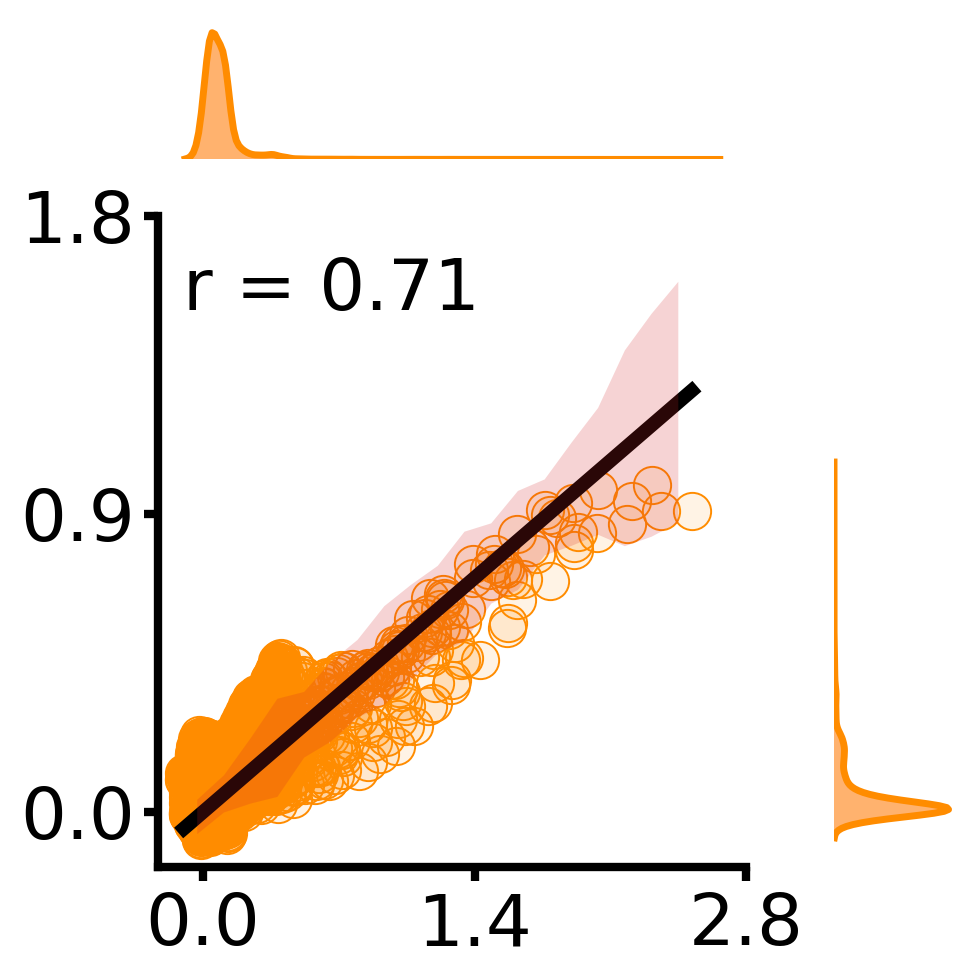

In [24]:
file_id = 7

# Load and align data
fmri_img = nib.load(fmri_list[file_id])
fmri_img = nib.Nifti1Image(
    fmri_img.get_fdata(),
    affine=mask_img.affine
)

fusi_img = nib.load(fusi_list[file_id])
fusi_img = nib.Nifti1Image(
    fusi_img.get_fdata(),
    affine=mask_img.affine

)

# Clean up aberrant values
fusi_map_lin = apply_mask(fusi_img, mask_img)
fmri_map_lin = apply_mask(fmri_img, mask_img)

valid_mask = (fmri_map_lin != 0) & (~np.isinf(fmri_map_lin)) & (~np.isnan(fmri_map_lin))

fusi_map_lin = fusi_map_lin[valid_mask]
fmri_map_lin = fmri_map_lin[valid_mask]

# Optional normalization (not used here)
# fusi_map_norm = ((1 + fusi_map_lin) / 2) ** 0.25
# fmri_map_norm = ((1 + fmri_map_lin) / 2) ** 0.25

# Build data dict and extract x, y
data_dict = {
    'fmri': fmri_map_lin,
    'fusi': fusi_map_lin,
}

x = data_dict['fmri']
y = data_dict['fusi']

# Call the plot function 

custom_join_plot(x, y)

## loop

In [25]:
save_dir = output_root / Path('fUSI-fMRI-correlation')
save_dir.mkdir(exist_ok = True, parents = True)

In [26]:
for file_id in tqdm(range(len(roi_list))):

    # Load and align data
    fmri_img = nib.load(fmri_list[file_id])
    fmri_img = nib.Nifti1Image(
        fmri_img.get_fdata(),
        affine=mask_img.affine
    )

    fusi_img = nib.load(fusi_list[file_id])
    fusi_img = nib.Nifti1Image(
        fusi_img.get_fdata(),
        affine=mask_img.affine
    )

    # Apply mask and clean aberrant values
    fusi_map_lin = apply_mask(fusi_img, mask_img)
    fmri_map_lin = apply_mask(fmri_img, mask_img)

    valid_mask = (fmri_map_lin != 0) & (~np.isinf(fmri_map_lin)) & (~np.isnan(fmri_map_lin))
    fusi_map_lin = fusi_map_lin[valid_mask]
    fmri_map_lin = fmri_map_lin[valid_mask]

    # Select data to use (non-normalized in this case)
    x = fmri_map_lin
    y = fusi_map_lin

    # Plot
    custom_join_plot(x, y)
    #plt.suptitle(roi_list[file_id])

    # Construct save name from file
    name_core = fmri_list[file_id].name.split('parcellationUnilateralDefaultN54-')[1].split('-Left-singleSlice_onesample')[0]

    save_png = save_dir / f'fUSI-fMRI_correlation_{name_core}.png'
    save_svg = save_dir / f'fUSI-fMRI_correlation_{name_core}.svg'

    plt.savefig(save_png)
    plt.savefig(save_svg)

    plt.close('all')


/tmp/ipykernel_3162094/1773758016.py:127: RuntimeWarning: divide by zero encountered in log10
  elif np.log10(pearsonr.pvalue) > -10:


# Correlation Matrix

## Parameters

In [27]:
# root_name = Path('/mnt/8TB/JC/1_DATA/2023-09-05_pilot/derivatives/02_merged/STC/CP-processing/derivatives/scrubbed/')

# fUSI

regimen = 'CPXISO'

root_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/preprocessed/')
root_dir = sorted([x for x in root_name.rglob('*') if x.is_file() and re.match(f'^.*{regimen}.*aCompCor.*pwd.nii.gz$', x.name)])

print(f'We found {len(root_dir)} files')

# Networks order

new_order = ['Iso', 'OLF', 'CTXsp', 'CNU', 'HPF', 'TH', 'HY', 'MB']

We found 13 files


In [28]:
nb_parcels = len(acro_df)

roi_list = []
roi_dict = {
    'acro':[],
    'id':[],
    'hemisphere':[],
    'AllenNetwork':[],
    'LudoNetwork':[]
}

for i,roi_id in enumerate(tqdm(list(acro_df['parcel_ids']))):
    
    roi_img = math_img(f"a == {roi_id}", a = parcellation)
    roi_list.append(roi_img)

    roi_dict['acro'].append(str(acro_df['acro'][i]))
    roi_dict['id'].append(acro_df['parcel_ids'][i])
    roi_dict['AllenNetwork'].append(str(acro_df['MetaRegion'][i]))
    roi_dict['LudoNetwork'].append(str(acro_df['Network'][i]))
    
    if acro_df['side'][i] == 'unilateralLeft':
       
        roi_dict['hemisphere'].append('left')

        
    else:
    
        roi_dict['hemisphere'].append('right')
        
roi_df = pd.DataFrame(roi_dict)
    

parcellation_img = parcellation
    
print(f'\nWe are using {len(roi_list)} ROIs\n')

################ Output

save_dir = output_root / Path(f'correlation_matrix/{regimen}')
save_dir.mkdir(exist_ok = True, parents = True)
    
print(roi_df.head(5))
print(roi_df.tail(5))

100%|██████████████████████████████████████| 108/108 [00:00<00:00, 989.31it/s]


We are using 108 ROIs

      acro  id hemisphere AllenNetwork LudoNetwork
0      MOp   1       left          Iso         LCN
1      MOs   2       left          Iso      DMNmid
2  SSp-bfd   3       left          Iso      DMNpln
3   SSp-ll   4       left          Iso      DMNpln
4   SSp-ul   5       left          Iso      DMNpln
      acro   id hemisphere AllenNetwork LudoNetwork
103  DORpm  104      right           TH       DMNth
104    PVZ  105      right           HY          BF
105    MEZ  106      right           HY          BF
106     LZ  107      right           HY          BF
107  MBmot  108      right           MB      DMNpln


## Parcel wise

In [29]:
nb_clusters = 2*len(new_order)

isort = np.array([])[:,None]
v = np.array([])

cluster_data = np.zeros(template_img.shape)

k = 0
boundary = []

for j,hemi in enumerate(['left', 'right']):

    for i,key in enumerate(new_order):

        # ind_list = np.argwhere(np.array((roi_df['LudoNetwork'] == key)&(roi_df['hemisphere'] == hemi)))
        ind_list = np.argwhere(np.array((roi_df['AllenNetwork'] == key)&(roi_df['hemisphere'] == hemi)))
        
        isort = np.concatenate((isort, ind_list)).astype(int)
        v = np.concatenate((v,(1+i+j*len(new_order))*np.ones(len(ind_list))))
        
        k = k+len(ind_list)
        boundary.append(k)
        
        for idx in ind_list:
        
            cluster_data[parcellation_img.get_fdata() == idx+1] = (1+i+j*len(new_order))
        
cluster_img = nib.Nifti1Image(
    cluster_data,
    affine = parcellation_img.affine
)
        
isort = isort.squeeze()
boundary = boundary[:-1]

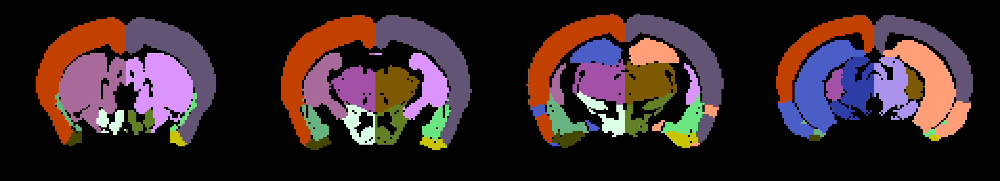

In [30]:
##################### Display networks Low resolution for visual check

vmax = cluster_img.get_fdata().max()

fig = display_modes(cluster_img, nb_col = 4, cmap = cc.cm['glasbey'], vmin = 0, vmax = vmax)

for i,ax in enumerate(fig.axes):

    img_2_display = (cluster_img.get_fdata() == 0).astype(float)[i,:,:]
    ax.imshow((img_2_display), cmap = 'Greys', vmin = 0, vmax = 1, alpha = 1.*(img_2_display), aspect = 0.1/0.11)

plt.tight_layout()

In [31]:
# Load images and compute connectomes

vect_list = []

for file_name in tqdm(root_dir):

    # load image
    img = nib.load(file_name)

    # extracts parcel wise timeseries
    masker = NiftiLabelsMasker(
        labels_img = parcellation_img,
        standardize = "zscore_sample"
    )

    signals = standardize(masker.fit_transform(img))[:,isort]

    # conputes correlation
    temp = np.arctanh(np.corrcoef(signals, rowvar=False))

    # stores correlation matrix as a vector
    vect_list.append(from_mat_2_vect(temp))

  0%|                                                  | 0/13 [00:00<?, ?it/s]/tmp/ipykernel_3162094/203144936.py:19: RuntimeWarning: divide by zero encountered in arctanh
  temp = np.arctanh(np.corrcoef(signals, rowvar=False))
  8%|███▏                                      | 1/13 [00:03<00:47,  3.93s/it]/tmp/ipykernel_3162094/203144936.py:19: RuntimeWarning: divide by zero encountered in arctanh
  temp = np.arctanh(np.corrcoef(signals, rowvar=False))
 15%|██████▍                                   | 2/13 [00:07<00:43,  3.94s/it]/tmp/ipykernel_3162094/203144936.py:19: RuntimeWarning: divide by zero encountered in arctanh
  temp = np.arctanh(np.corrcoef(signals, rowvar=False))
 23%|█████████▋                                | 3/13 [00:11<00:38,  3.89s/it]/tmp/ipykernel_3162094/203144936.py:19: RuntimeWarning: divide by zero encountered in arctanh
  temp = np.arctanh(np.corrcoef(signals, rowvar=False))
 31%|████████████▉                             | 4/13 [00:15<00:35,  3.90s/it]/tmp/ipyke

In [32]:
# perform stats

res_wilcoxon = wilcoxon(np.array(vect_list))

res_fdr = multipletests(
    res_wilcoxon.pvalue,
    alpha = 0.05,
    method = 'fdr_bh',
)

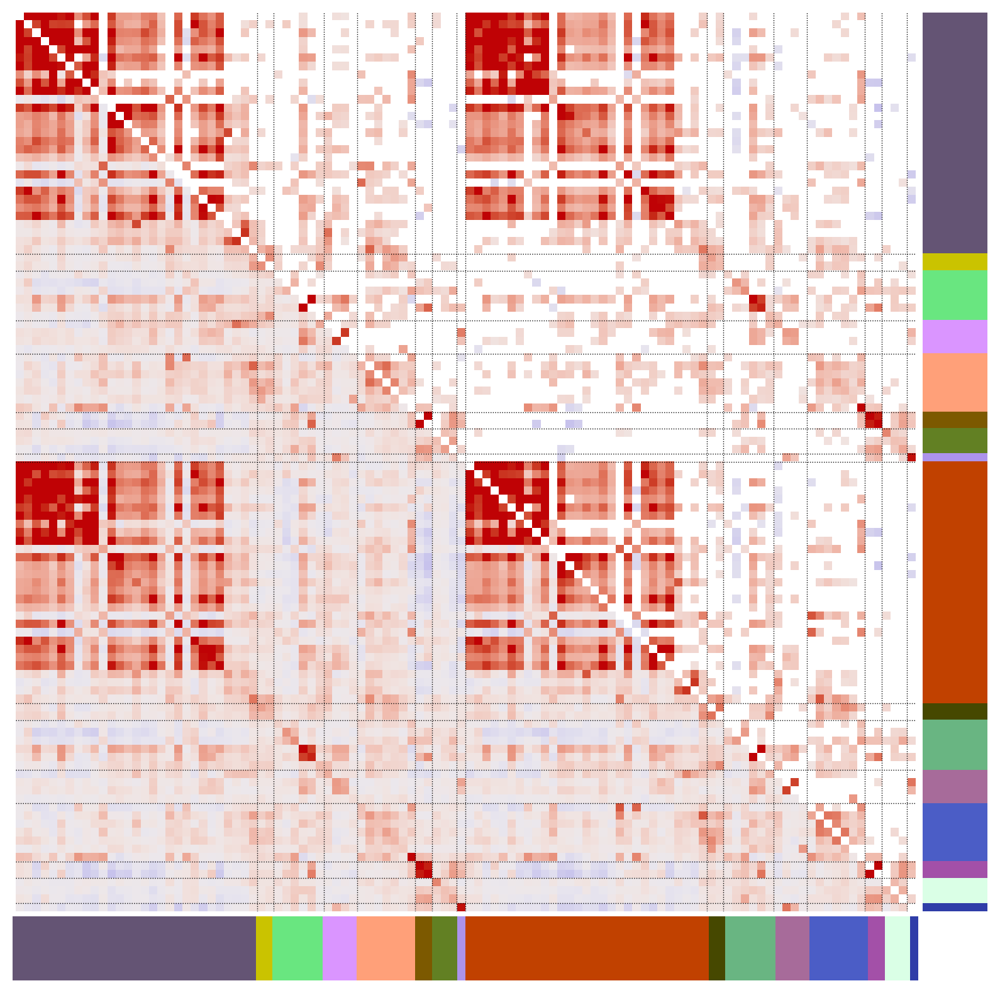

In [33]:
# Display matrices

fig, ax = plt.subplots(2,2,figsize = [10,10],dpi = 200,
                  gridspec_kw={
                      'height_ratios': [14, 1],
                      'width_ratios': [14, 1],
                      'wspace' : 0.01,
                      'hspace' : 0.01,
                  },
)

for a in ax.flatten():
    a.axis('off')

# Average

avg_mat = np.ones((nb_parcels, nb_parcels))*np.nan
avg_mat[np.tril(np.ones((nb_parcels, nb_parcels)), -1).astype(bool)] = np.tanh(np.array(vect_list).mean(0))

# thresholded

signif_mat = np.ones((nb_parcels, nb_parcels))*np.nan
signif_vect = np.tanh(np.array(vect_list).mean(0)).copy()
signif_vect[res_fdr[0] == 0] = np.inf
signif_mat[np.tril(np.ones((nb_parcels, nb_parcels)), -1).astype(bool)] = signif_vect

# reorder merge

reordered_avg_mat = avg_mat[isort,:][:,isort].copy()

for i in range(nb_parcels):
    for j in range(i):
        if np.isnan(reordered_avg_mat[i,j]):
            reordered_avg_mat[i,j] = reordered_avg_mat[j,i]
            reordered_avg_mat[j,i] = np.nan

reordered_signif_mat = signif_mat[isort,:][:,isort].copy()

for i in range(nb_parcels):
    for j in range(i):
        if np.isnan(reordered_signif_mat[j,i]):
            reordered_signif_mat[j,i] = reordered_signif_mat[i,j]
            reordered_signif_mat[i,j] = np.nan

matrix_2_display = reordered_avg_mat.copy()

for i in range(nb_parcels):
    for j in range(i):
        matrix_2_display[j,i] = reordered_signif_mat[j,i]

# display

ax[0,0].imshow(matrix_2_display, cmap = cc.cm['CET_D1'], vmin = -0.5, vmax = 0.5)
ax[0,0].axis('off')

for k in boundary:
    
    ax[0,0].axvline(k-0.5, c = 'k', color = 'k', ls = ':', lw = 0.5)
    ax[0,0].axhline(k-0.5, c = 'k', color = 'k', ls = ':', lw = 0.5)

# Legend bottom
ax[1,0].imshow(v[:,None].T, aspect = 'auto', cmap = cc.cm['glasbey'], vmin = 0, vmax = vmax)

# legend right

ax[0,1].imshow(v[None,:].T, aspect = 'auto', cmap = cc.cm['glasbey'], vmin = 0, vmax = vmax)

save_name = save_dir / 'FC_parcel_wise.png'
plt.savefig(save_name)

save_name = save_dir / 'FC_parcel_wise.svg'
plt.savefig(save_name)

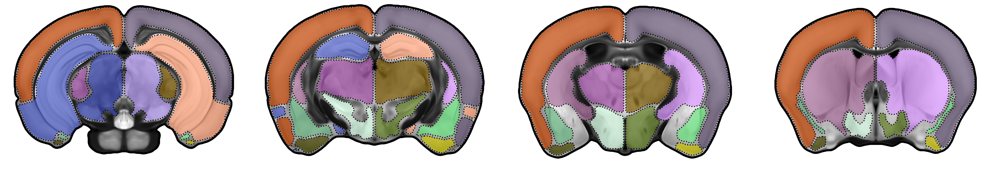

In [35]:
fig,ax = plt.subplots(1,nb_col, figsize = (7*nb_col, 5), dpi = 200)

vmax = cluster_img.get_fdata().max()

# Filters the cluster display

cluster_cleaned_data = np.zeros(cluster_img.shape)
for i in range(4):
    cluster_cleaned_data[i,:,:] = fill_holes_sw(cluster_img.get_fdata()[i,:,:])

cluster_cleaned_img = nib.Nifti1Image(
    cluster_cleaned_data,
    affine = cluster_img.affine
)

cluster_hr_img = resample_img(
    cluster_cleaned_img,
    target_affine=template_hr_img.affine,
    target_shape=template_hr_img.shape,
    interpolation='nearest',
    copy_header=True,
    force_resample=True
)

#

for slice_id in range(nb_col):
    
    ######################## Template

    img_2_display = template_hr_img.get_fdata()[slice_id,:,:].copy()
    current_mask = 1.*(binary_fill_holes(img_2_display>10))
    img_2_display[current_mask == 0] = np.nan

    ax[nb_col-slice_id-1].imshow(img_2_display, cmap = 'Greys_r', vmin = template_vmin, vmax = template_vmax)

    ax[nb_col-slice_id-1].contour(gaussian_filter(1.*current_mask,2), levels = [0.5], colors = ['k'], linewidths = [4])

    # ######################## image

    img_2_display = smooth_high_res_cluster(
        cluster_hr_img.get_fdata()[slice_id,:,:].copy(),
        sigma = 4,
        th = 0.25
    )
    img_2_display[current_mask == 0] = 0

    ax[nb_col-slice_id-1].imshow(img_2_display, cmap = cc.cm['glasbey'], vmin = 0, vmax = vmax, alpha = 0.7*(img_2_display>0), interpolation = 'none')
    for level in np.unique(img_2_display)[1:]:
        ax[nb_col-slice_id-1].contour(img_2_display==level, levels = [0.5], colors = ['k'], linewidths = [2], linestyles = ':')

    ax[nb_col-slice_id-1].axis('off')

plt.tight_layout()

save_name = save_dir / 'FC_parcel_AllenNetworks.png'
plt.savefig(save_name)
save_name = save_dir / 'FC_parcel_AllenNetworks.svg'
plt.savefig(save_name)

## FC clustering

Clusters are computed on a symmetrised connectivity matrix `local_matrix`

### Parameters

In [36]:
nb_cluster = 8
nb_PCs = 100

### Clustering

In [37]:
local_mat = avg_mat.copy()
# nan must be removed for rastermap
local_mat[np.isnan(local_mat)] = 0
# Symmetrisation
local_mat = local_mat + (local_mat).T

(np.float64(-0.5), np.float64(107.5), np.float64(107.5), np.float64(-0.5))

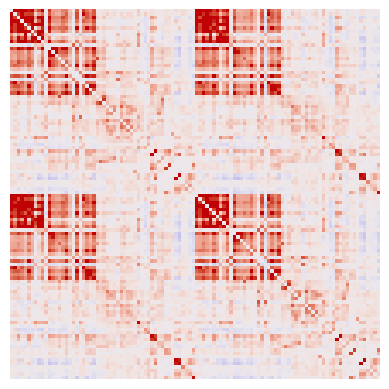

In [38]:
# display for visual checks

plt.imshow(local_mat, cmap = cc.cm['CET_D1'], vmin = -0.5, vmax = 0.5)
plt.axis('off')

In [39]:
model = Rastermap(
    n_PCs=nb_PCs, 
    n_clusters=nb_cluster,  
    time_lag_window=0
).fit(local_mat)

# extract clusters

y = model.embedding # neurons x 1
isort = model.isort

# Reorders unilateral = split left and right parts of the clusters

neworder = (np.arange(nb_cluster)+1)

clust_vect = (model.embedding_clust+1).astype('uint32')
clust_data = np.zeros(clust_vect.shape)

v_left = {f'{i}':[] for i in neworder}
v_right = {f'{i}':[] for i in neworder}

boundary_left = {f'{i}':[] for i in neworder}
boundary_right = {f'{i}':[] for i in neworder}

ireordered_left = {f'{i}':[] for i in neworder}
ireordered_right = {f'{i}':[] for i in neworder}

for idx, (clust_id, current_index) in enumerate(zip(clust_vect, range(nb_parcels))):

    if roi_df.iloc[idx]['hemisphere'] == 'left':

        v_left[str(clust_id)].append(clust_id)
        boundary_left[str(clust_id)].append(1)
        ireordered_left[str(clust_id)].append(idx)

    if roi_df.iloc[idx]['hemisphere'] == 'right':

        v_right[str(clust_id)].append(clust_id)
        boundary_right[str(clust_id)].append(1)
        ireordered_right[str(clust_id)].append(idx)

# patching back together

v = []
boundary = [0]
ireordered = []

for i in neworder:

    v = v + v_left[str(i)]
    boundary.append(boundary[-1] + sum(boundary_left[str(i)]))
    ireordered = ireordered + ireordered_left[str(i)]

for i in neworder:

    v = v + [x+nb_cluster for x in  v_right[str(i)]]
    boundary.append(boundary[-1] + sum(boundary_right[str(i)]))
    ireordered = ireordered + ireordered_right[str(i)]

v = np.array(v)
boundary = np.array(boundary)

2026-07-20 21:47:00,691 [INFO] normalizing data across axis=1
2026-07-20 21:47:00,692 [INFO] projecting out mean along axis=0
2026-07-20 21:47:00,693 [INFO] data normalized, 0.00sec
2026-07-20 21:47:00,693 [INFO] sorting activity: 108 valid samples by 108 timepoints
2026-07-20 21:47:00,832 [INFO] n_PCs = 100 computed, 0.14sec
2026-07-20 21:47:00,867 [INFO] 8 clusters computed, time 0.18sec
2026-07-20 21:47:01,064 [INFO] clusters sorted, time 0.37sec
2026-07-20 21:47:01,068 [INFO] clusters upsampled, time 0.38sec
2026-07-20 21:47:01,069 [INFO] rastermap complete, time 0.38sec


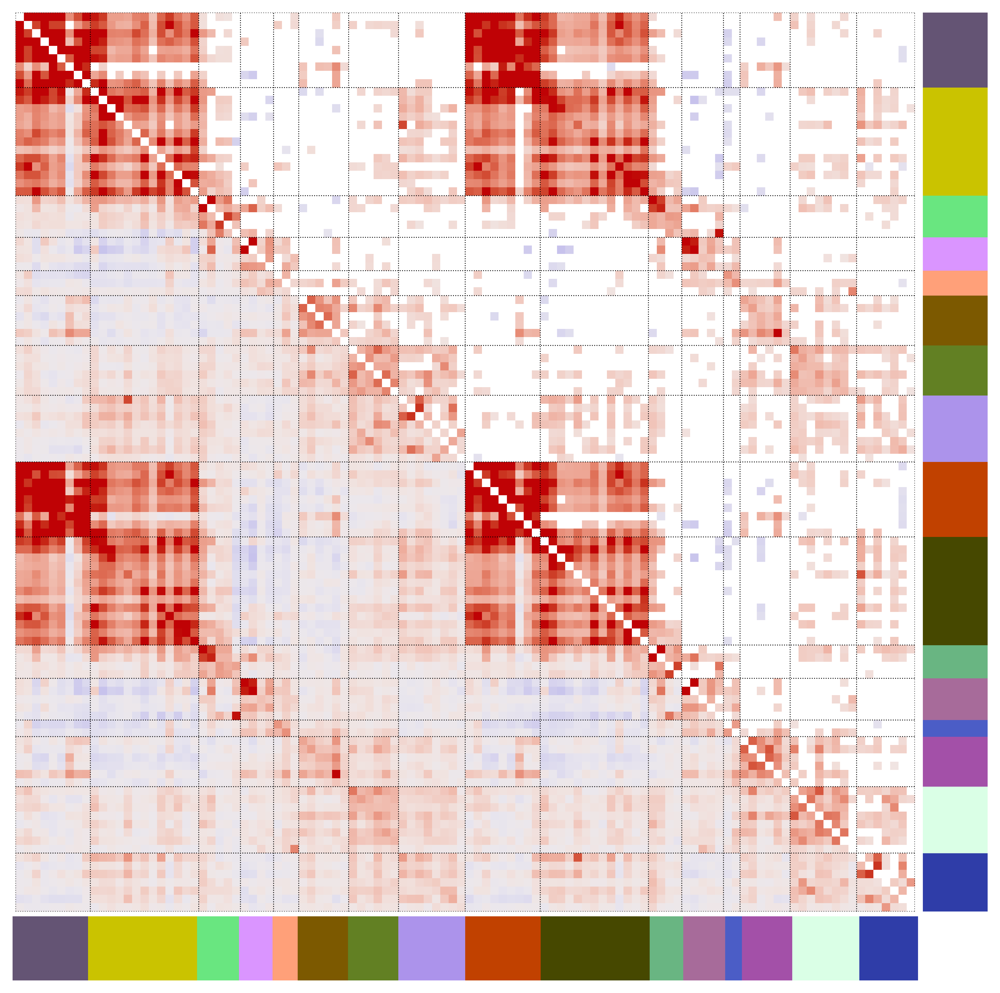

In [40]:
# Display reordered matrices

fig, ax = plt.subplots(2,2,figsize = [10,10],dpi = 600,
                  gridspec_kw={
                      'height_ratios': [14, 1],
                      'width_ratios': [14, 1],
                      'wspace' : 0.01,
                      'hspace' : 0.01,
                  },
)

for a in ax.flatten():
    a.axis('off')

# display

reordered_avg_mat = avg_mat[ireordered,:][:,ireordered].copy()

for i in range(nb_parcels):
    for j in range(i):
        if np.isnan(reordered_avg_mat[i,j]):
            reordered_avg_mat[i,j] = reordered_avg_mat[j,i]
            reordered_avg_mat[j,i] = np.nan

reordered_signif_mat = signif_mat[ireordered,:][:,ireordered].copy()

for i in range(nb_parcels):
    for j in range(i):
        if np.isnan(reordered_signif_mat[j,i]):
            reordered_signif_mat[j,i] = reordered_signif_mat[i,j]
            reordered_signif_mat[i,j] = np.nan

matrix_2_display = reordered_avg_mat.copy()

for i in range(nb_parcels):
    for j in range(i):
        matrix_2_display[j,i] = reordered_signif_mat[j,i]


ax[0,0].imshow(matrix_2_display, cmap = cc.cm['CET_D1'], vmin = -0.5, vmax = 0.5, interpolation = 'nearest')
ax[0,0].axis('off')

for k in boundary:
    
    ax[0,0].axvline(k-0.5, c = 'k', color = 'k', ls = ':', lw = 0.5)
    ax[0,0].axhline(k-0.5, c = 'k', color = 'k', ls = ':', lw = 0.5)

# Legend bottom
ax[1,0].imshow(v[:,None].T, aspect = 'auto', cmap = cc.cm['glasbey'], vmin = 0, vmax = 2*nb_cluster)

# legend right

ax[0,1].imshow(v[None,:].T, aspect = 'auto', cmap = cc.cm['glasbey'], vmin = 0, vmax = 2*nb_cluster)

save_name = save_dir / 'FC_cluster_wise.png'
plt.savefig(save_name)

save_name = save_dir / 'FC_cluster_wise.svg'
plt.savefig(save_name)

In [41]:
cluster_data = np.zeros(parcellation_img.shape)

# Bilateral clusters = split cluster in left and right

for idx, val in zip(ireordered, v):

    cluster_data[parcellation_img.get_fdata() == idx+1] = val

cluster_img = nib.Nifti1Image(
    cluster_data,
    affine = parcellation_img.affine
)

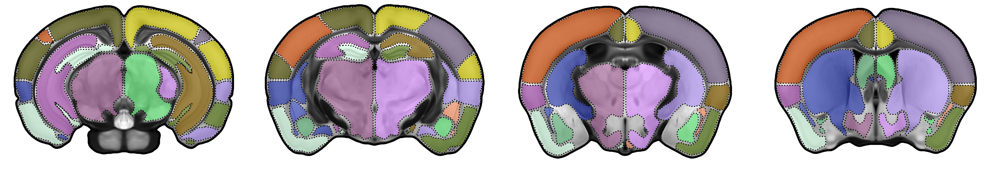

In [42]:
fig,ax = plt.subplots(1,nb_col, figsize = (7*nb_col, 5), dpi = 200)

# Filters the cluster display

cluster_cleaned_data = np.zeros(cluster_img.shape)
for i in range(4):
    cluster_cleaned_data[i,:,:] = fill_holes_sw(cluster_img.get_fdata()[i,:,:])

cluster_cleaned_img = nib.Nifti1Image(
    cluster_cleaned_data,
    affine = cluster_img.affine
)

cluster_hr_img = resample_img(
    cluster_cleaned_img,
    target_affine=template_hr_img.affine,
    target_shape=template_hr_img.shape,
    interpolation='nearest',
    copy_header=True,
    force_resample=True
)

#

for slice_id in range(nb_col):
    
    ######################## Template

    img_2_display = template_hr_img.get_fdata()[slice_id,:,:].copy()
    current_mask = 1.*(binary_fill_holes(img_2_display>10))
    img_2_display[current_mask == 0] = np.nan

    ax[-slice_id-1].imshow(img_2_display, cmap = 'Greys_r', vmin = template_vmin, vmax = template_vmax)

    ax[-slice_id-1].contour(gaussian_filter(1.*current_mask,2), levels = [0.5], colors = ['k'], linewidths = [4])

    # ######################## image

    img_2_display = smooth_high_res_cluster(
        cluster_hr_img.get_fdata()[slice_id,:,:].copy(),
        sigma = 4,
        th = 0.25
    )
    img_2_display[current_mask == 0] = 0

    ax[-slice_id-1].imshow(img_2_display, cmap = cc.cm['glasbey'], vmin = 0, vmax = 2*nb_cluster, alpha = 0.7*(img_2_display>0), interpolation = 'nearest')
    for level in np.unique(img_2_display)[1:]:
        ax[-slice_id-1].contour(img_2_display==level, levels = [0.5], colors = ['k'], linewidths = [2], linestyles = ':')

    ax[-slice_id-1].axis('off')

plt.tight_layout()

save_name = save_dir / 'FC_parcel_ClusterNetworks.png'
plt.savefig(save_name)
save_name = save_dir / 'FC_parcel_ClusterNetworks.svg'
plt.savefig(save_name)

# ICA

## fUSI

### Parameters

In [43]:
################ ICA parameters

n_components = 3

################ Data

regimen = 'CPXISO'

root_name = Path('/media/DATA/jmariani/1_data/2026-04-13_PepeMariani/2026-02-03_PepeMariani_fUSI-anaesthetised/derivatives/preprocessed/')
root_dir = sorted([x for x in root_name.rglob('*') if x.is_file() and re.match(f'^.*{regimen}.*aCompCor.*pwd.nii.gz$', x.name)])

print(f'We found {len(root_dir)} files')

################ Output directory

save_dir = output_root / Path('ICA/fUSI')
save_dir.mkdir(exist_ok = True, parents = True)

We found 13 files


### Computes ICA

Estimates ICA components with Dictionary learning method based on [nilearn documentation](https://nilearn.github.io/stable/auto_examples/03_connectivity/plot_compare_decomposition.html).

In [44]:
# Initialize DictLearning object

dict_learn = DictLearning(
    mask = mask_img,
    n_components=n_components,
    memory="nilearn_cache",
    memory_level=1,
    random_state=0,
    standardize="zscore_sample",
    verbose=1,
    smoothing_fwhm=0.3,
    n_jobs = 18
)

# fit ICA on the data 

dict_learn.fit(root_dir)

[DictLearning.fit] Loading data
[DictLearning.fit] Learning initial components


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.


[DictLearning.fit] Computing initial loadings
[DictLearning.fit]  Learning dictionary


,"n_components n_components: :obj:`int`, default=20Number of components to extract.",3
,"n_epochs n_epochs: :obj:`float`, default=1Number of epochs the algorithm should run on the data.",1
,"alpha alpha: :obj:`float`, default=10Sparsity controlling parameter.",10
,"reduction_ratio reduction_ratio: 'auto' or :obj:`float` between 0. and 1., default='auto'- Between 0. or 1. : controls data reduction in the temporal domain. 1. means no reduction, < 1. calls for an SVD based reduction.- if set to 'auto', estimator will set the number of components per reduced session to be n_components.",'auto'
,"dict_init dict_init: Niimg-like object or :obj:`~nilearn.surface.SurfaceImage` or None, default=NoneInitial estimation of dictionary maps. Would be computed from CanICA ifnot provided.",None
,"random_state random_state: :obj:`int` or np.random.RandomState, optionalPseudo-random number generator state used for random sampling.",0
,"batch_size batch_size: :obj:`int`, default=20The number of samples to take in each batch.",20
,"method method: {'cd', 'lars'}, default='cd'Coding method used by sklearn backend. Below are the possible values.lars: uses the least angle regression method to solve the lasso problem(linear_model.lars_path)cd: uses the coordinate descent method to compute theLasso solution (linear_model.Lasso). Lars will be faster ifthe estimated components are sparse.",'cd'
,"mask mask: Niimg-like object, :obj:`~nilearn.maskers.MultiNiftiMasker` or :obj:`~nilearn.surface.SurfaceImage` or :obj:`~nilearn.maskers.MultiSurfaceMasker` object, or None default=NoneMask to be used on data.If an instance of masker is passed,then its mask will be used.If no mask is given, for Nifti images,it will be computed automatically by a MultiNiftiMaskerwith default parameters;for surface images, all the vertices will be used.",<nibabel.nift...x7cd2740da650>
,"smoothing_fwhm smoothing_fwhm: :obj:`float` or :obj:`int` or None, optional.If `smoothing_fwhm` is not `None`,it gives the :term:`full-width at half maximum` in millimetersof the spatial smoothing to apply to the signal.default=4mm.",0.3
,"standardize standardize: any of: 'zscore_sample', 'zscore', 'psc', True, False or None; default=TrueStrategy to standardize the signal:- ``'zscore_sample'``: The signal is z-scored. Timeseries are shifted to zero mean and scaled to unit variance. Uses sample std.- ``'psc'``: Timeseries are shifted to zero mean value and scaled to percent signal change (as compared to original mean signal).- ``True``: The signal is z-scored (same as option `zscore`). Timeseries are shifted to zero mean and scaled to unit variance. .. nilearn_deprecated:: 0.13.0 In nilearn version 0.15.0, ``True`` will be replaced by ``'zscore_sample'``.- ``False``: Do not standardize the data. .. nilearn_deprecated:: 0.13.0 In nilearn version 0.15.0, ``False`` will be replaced by ``None``... nilearn_deprecated:: 0.13.0 The default will be changed to ``'zscore_sample'`` in version 0.15.0.",'zscore_sample'


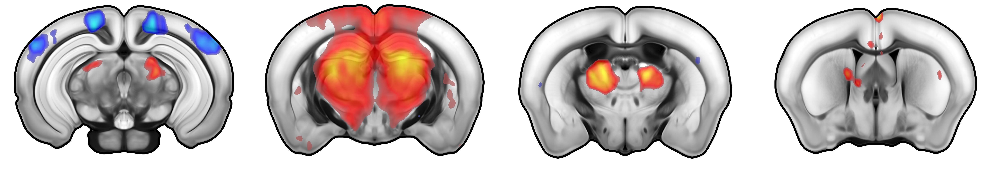

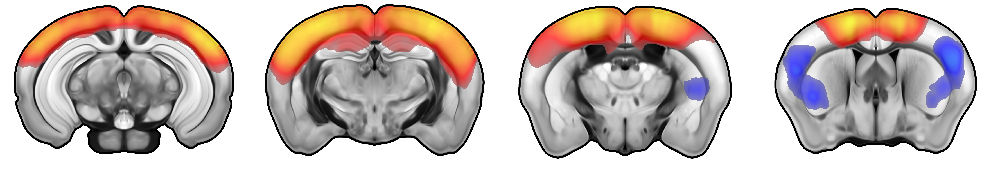

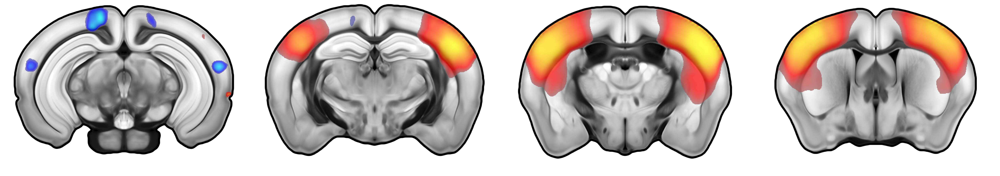

In [45]:
# Upsamples the results to high resolution space

components_img = dict_learn.components_img_

ic_hr_img = resample_img(
    components_img,
    target_affine=template_hr_img.affine,
    target_shape=template_hr_img.shape,
    interpolation='continuous',
    copy_header=True,
    force_resample=True
)

# Display

for IC_id in range(n_components):
    
    nb_col = 4
    
    fig,ax = plt.subplots(1,nb_col, figsize = (7*nb_col, 5), dpi = 200)
    
    for slice_id in range(nb_col):
        
        ######################## Template
    
        img_2_display = template_hr_img.get_fdata()[slice_id,:,:].copy()
        current_mask = 1.*(binary_fill_holes(img_2_display>10))
        img_2_display[current_mask == 0] = np.nan
    
        ax[-slice_id-1].imshow(img_2_display, cmap = 'Greys_r', vmin = template_vmin, vmax = template_vmax)
    
        # ######################## image
    
        img_2_display = ic_hr_img.get_fdata()[slice_id,:,:,IC_id].copy()
        img_2_display[current_mask == 0] = 0
        cm = abs(img_2_display).max()
    
        ax[-slice_id-1].imshow(img_2_display, cmap = mymap, vmin = -cm, vmax = cm, alpha = 0.7*(abs(img_2_display)>cm/10), interpolation = 'none')
    
        # ######################## Contour
        
        ax[-slice_id-1].contour(gaussian_filter(1.*current_mask,2), levels = [0.5], colors = ['k'], linewidths = [4])
        
        ax[-slice_id-1].axis('off')
    
    plt.tight_layout()
    
    save_name = save_dir / f'ICA-{IC_id+1}.png'
    plt.savefig(save_name)
    save_name = save_dir / f'ICA-{IC_id+1}.svg'
    plt.savefig(save_name)